In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
df=pd.read_csv("OnlineNewsPopularity.csv")
df.head()

,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731,12,219,0.663594,1.0,0.815385,4,2,1,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731,9,255,0.604743,1.0,0.791946,3,1,1,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731,9,211,0.575130,1.0,0.663866,3,1,1,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731,9,531,0.503788,1.0,0.665635,9,0,1,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731,13,1072,0.415646,1.0,0.540890,19,19,20,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


In [3]:
# ONLINE NEWS POPULARITY DATASET - COLUMN EXPLANATIONS

# 1. url
# Contains the website link of the news article.

# 2. timedelta
# Tells us how many days passed between publishing the article
# and collecting the dataset.

# 3. n_tokens_title
# Tells us how many words are present in the article's title.

# 4. n_tokens_content
# Tells us how many words are present in the main content of the article.

# 5. n_unique_tokens
# Tells us how many different words are used in the article
# compared to the total number of words.

# 6. n_non_stop_words
# Tells us the proportion of words that are not common words
# like "the", "is", "and" or "a".

# 7. n_non_stop_unique_tokens
# Tells us the proportion of different words after removing
# common words and repeated words.

# 8. num_hrefs
# Tells us the total number of links present in the article.

# 9. num_self_hrefs
# Tells us how many links point to other articles on Mashable.

# 10. num_imgs
# Tells us the total number of images present in the article.

# 11. num_videos
# Tells us the total number of videos present in the article.

# 12. average_token_length
# Tells us the average number of characters present in each word.

# 13. num_keywords
# Tells us how many keywords are assigned to the article.

# 14. data_channel_is_lifestyle
# 1 means the article belongs to the Lifestyle category.
# 0 means it does not.

# 15. data_channel_is_entertainment
# 1 means the article belongs to the Entertainment category.
# 0 means it does not.

# 16. data_channel_is_bus
# 1 means the article belongs to the Business category.
# 0 means it does not.

# 17. data_channel_is_socmed
# 1 means the article belongs to the Social Media category.
# 0 means it does not.

# 18. data_channel_is_tech
# 1 means the article belongs to the Technology category.
# 0 means it does not.

# 19. data_channel_is_world
# 1 means the article belongs to the World News category.
# 0 means it does not.

# 20. kw_min_min
# Tells us the smallest minimum historical number of shares
# among the article's keywords.

# 21. kw_max_min
# Tells us the largest minimum historical number of shares
# among the article's keywords.

# 22. kw_avg_min
# Tells us the average of the minimum historical shares
# among the article's keywords.

# 23. kw_min_max
# Tells us the smallest maximum historical number of shares
# among the article's keywords.

# 24. kw_max_max
# Tells us the largest maximum historical number of shares
# among the article's keywords.

# 25. kw_avg_max
# Tells us the average of the maximum historical shares
# among the article's keywords.

# 26. kw_min_avg
# Tells us the smallest average historical number of shares
# among the article's keywords.

# 27. kw_max_avg
# Tells us the largest average historical number of shares
# among the article's keywords.

# 28. kw_avg_avg
# Tells us the average historical number of shares
# among the article's keywords.

# 29. self_reference_min_shares
# Tells us the smallest number of shares received by other
# Mashable articles linked inside the current article.

# 30. self_reference_max_shares
# Tells us the largest number of shares received by other
# Mashable articles linked inside the current article.

# 31. self_reference_avg_sharess
# Tells us the average number of shares received by other
# Mashable articles linked inside the current article.

# 32. weekday_is_monday
# 1 means the article was published on Monday.
# 0 means it was not.

# 33. weekday_is_tuesday
# 1 means the article was published on Tuesday.
# 0 means it was not.

# 34. weekday_is_wednesday
# 1 means the article was published on Wednesday.
# 0 means it was not.

# 35. weekday_is_thursday
# 1 means the article was published on Thursday.
# 0 means it was not.

# 36. weekday_is_friday
# 1 means the article was published on Friday.
# 0 means it was not.

# 37. weekday_is_saturday
# 1 means the article was published on Saturday.
# 0 means it was not.

# 38. weekday_is_sunday
# 1 means the article was published on Sunday.
# 0 means it was not.

# 39. is_weekend
# 1 means the article was published on Saturday or Sunday.
# 0 means it was published on a weekday.

# 40. global_subjectivity
# Tells us how much the complete article contains opinions
# and personal feelings instead of just facts.

# 41. global_sentiment_polarity
# Tells us whether the overall article has a positive
# or negative emotional tone.

# 42. global_rate_positive_words
# Tells us the proportion of positive words among ALL words
# in the article, including neutral words.

# 43. global_rate_negative_words
# Tells us the proportion of negative words among ALL words
# in the article, including neutral words.

# 44. rate_positive_words
# Tells us the proportion of positive words among only
# positive and negative words. Neutral words are excluded.

# 45. rate_negative_words
# Tells us the proportion of negative words among only
# positive and negative words. Neutral words are excluded.

# 46. avg_positive_polarity
# Tells us the average positivity score of all positive words
# present in the article.

# 47. min_positive_polarity
# Tells us the lowest positivity score among positive words
# present in the article.

# 48. max_positive_polarity
# Tells us the highest positivity score among positive words
# present in the article.

# 49. avg_negative_polarity
# Tells us the average negativity score of all negative words
# present in the article.

# 50. min_negative_polarity
# Tells us the most negative sentiment score among negative
# words present in the article.

# 51. max_negative_polarity
# Tells us the least negative sentiment score among negative
# words present in the article.

# 52. title_subjectivity
# Tells us how much the article's title contains opinions
# and personal feelings instead of just facts.

# 53. title_sentiment_polarity
# Tells us whether the article's title has a positive
# or negative emotional tone.

# 54. abs_title_subjectivity
# Tells us how far the title's subjectivity is from the
# neutral level, without considering the direction.

# 55. abs_title_sentiment_polarity
# Tells us how strong the positive or negative sentiment
# of the title is, without considering whether it is positive
# or negative. It removes the negative sign if present.

# 56. shares
# Tells us the total number of times the article was shared
# on social media.
# This is our TARGET COLUMN (y) that we want to predict.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39644 entries, 0 to 39643
Data columns (total 56 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   url                             39644 non-null  str    
 1    timedelta                      39644 non-null  int64  
 2    n_tokens_title                 39644 non-null  int64  
 3    n_tokens_content               39644 non-null  int64  
 4    n_unique_tokens                39644 non-null  float64
 5    n_non_stop_words               39644 non-null  float64
 6    n_non_stop_unique_tokens       39644 non-null  float64
 7    num_hrefs                      39644 non-null  int64  
 8    num_self_hrefs                 39644 non-null  int64  
 9    num_imgs                       39644 non-null  int64  
 10   num_videos                     39644 non-null  int64  
 11   average_token_length           39644 non-null  float64
 12   num_keywords                   39644 non-n

In [5]:
df.drop_duplicates(inplace=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39644 entries, 0 to 39643
Data columns (total 56 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   url                             39644 non-null  str    
 1    timedelta                      39644 non-null  int64  
 2    n_tokens_title                 39644 non-null  int64  
 3    n_tokens_content               39644 non-null  int64  
 4    n_unique_tokens                39644 non-null  float64
 5    n_non_stop_words               39644 non-null  float64
 6    n_non_stop_unique_tokens       39644 non-null  float64
 7    num_hrefs                      39644 non-null  int64  
 8    num_self_hrefs                 39644 non-null  int64  
 9    num_imgs                       39644 non-null  int64  
 10   num_videos                     39644 non-null  int64  
 11   average_token_length           39644 non-null  float64
 12   num_keywords                   39644 non-n

In [6]:
# Outliers were retained because extreme values represent genuine variations 
# in article popularity, including highly viral articles, 
# and removing them could result in the loss of valuable information.

In [7]:
# Skewness was not reduced because the asymmetrical distributions 
# reflect the natural characteristics of the dataset, and 
# transforming them could alter meaningful patterns in the data.

In [8]:
# Categorical encoding was not required because the dataset 
# primarily consists of numerical features and already encoded binary indicator variables; 
# the URL column was excluded from model training.
df.columns = df.columns.str.strip()

In [9]:
numeric_features = df.select_dtypes(include="number").columns

# Columns to exclude
excluded_columns = [
    "shares",
    "kw_min_min",
    "kw_max_min",
    "kw_min_max",
    "kw_max_max",
    "kw_min_avg",
    "kw_max_avg",
    "self_reference_min_shares",
    "self_reference_max_shares",
    "self_reference_avg_shares"
]

# Remove excluded columns from numeric features
selected_features = [
    col for col in numeric_features
    if col not in excluded_columns
]

# X1,y1: XGBoost
X1 = df[selected_features].copy()
y1 = df["shares"]


# X2,y2: Logistic Regression
X2 = X1.copy()
median_shares = y1.median()
y2 = (y1 >= median_shares).astype(int)


# X3,y3: KNN
weekday_columns = [
    "weekday_is_monday",
    "weekday_is_tuesday",
    "weekday_is_wednesday",
    "weekday_is_thursday",
    "weekday_is_friday",
    "weekday_is_saturday",
    "weekday_is_sunday"
]

X3 = X1.copy()
y3 = df["shares"]
weekday = df[weekday_columns].idxmax(axis=1)

# Phase 2

In [10]:
# Plotting libraries for Phase 2 (pandas and numpy were already imported in Phase 1)
import matplotlib.pyplot as plt
import seaborn as sns

# One clean chart style for every plot below
sns.set_theme(style="whitegrid")

In [11]:
# ---------- Setup for Phase 2 ----------
# Work on a copy so the Phase 1 dataframe (df) is never changed
eda_df = df.copy()

# Groups of 0/1 indicator columns
channel_columns = [c for c in eda_df.columns if c.startswith("data_channel_is_")]
day_columns = [
    "weekday_is_monday", "weekday_is_tuesday", "weekday_is_wednesday",
    "weekday_is_thursday", "weekday_is_friday", "weekday_is_saturday",
    "weekday_is_sunday",
]
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Numeric columns only (url is text, so it is left out)
numeric_df = eda_df.select_dtypes(include="number")

# One "channel" column built from the six 0/1 topic columns
eda_df["channel"] = eda_df[channel_columns].idxmax(axis=1).str.replace("data_channel_is_", "")
# Articles that belong to none of the six topics are labelled "Other"
eda_df.loc[eda_df[channel_columns].sum(axis=1) == 0, "channel"] = "Other"

# One "weekday" column built from the seven 0/1 day columns
eda_df["weekday"] = eda_df[day_columns].idxmax(axis=1).str.replace("weekday_is_", "").str.capitalize()

In [12]:
# ---------- 2.1 Descriptive statistics ----------
# describe() gives count, mean, std, min, quartiles (50% = median) and max per column
stats = numeric_df.describe().T

# Skewness added: a large positive value means a long tail of very high values
stats["skew"] = numeric_df.skew()

stats

,count,mean,std,min,25%,50%,75%,max,skew
timedelta,39644.0,354.530471,214.163767,8.00000,164.000000,339.000000,542.000000,731.000000,0.120504
n_tokens_title,39644.0,10.398749,2.114037,2.00000,9.000000,10.000000,12.000000,23.000000,0.165320
n_tokens_content,39644.0,546.514731,471.107508,0.00000,246.000000,409.000000,716.000000,8474.000000,2.945422
n_unique_tokens,39644.0,0.548216,3.520708,0.00000,0.470870,0.539226,0.608696,701.000000,198.655116
n_non_stop_words,39644.0,0.996469,5.231231,0.00000,1.000000,1.000000,1.000000,1042.000000,198.792445
n_non_stop_unique_tokens,39644.0,0.689175,3.264816,0.00000,0.625739,0.690476,0.754630,650.000000,198.443294
num_hrefs,39644.0,10.883690,11.332017,0.00000,4.000000,8.000000,14.000000,304.000000,4.013495
num_self_hrefs,39644.0,3.293638,3.855141,0.00000,1.000000,3.000000,4.000000,116.000000,5.172751
num_imgs,39644.0,4.544143,8.309434,0.00000,1.000000,1.000000,4.000000,128.000000,3.946596
num_videos,39644.0,1.249874,4.107855,0.00000,0.000000,0.000000,1.000000,91.000000,7.019533


In [13]:
# Focus on the target column: shares
print("Mean   :", round(eda_df["shares"].mean(), 1))
print("Median :", eda_df["shares"].median())
print("Std    :", round(eda_df["shares"].std(), 1))
# Mean far above the median means a few very popular articles pull the average up

Mean   : 3395.4
Median : 1400.0
Std    : 11627.0


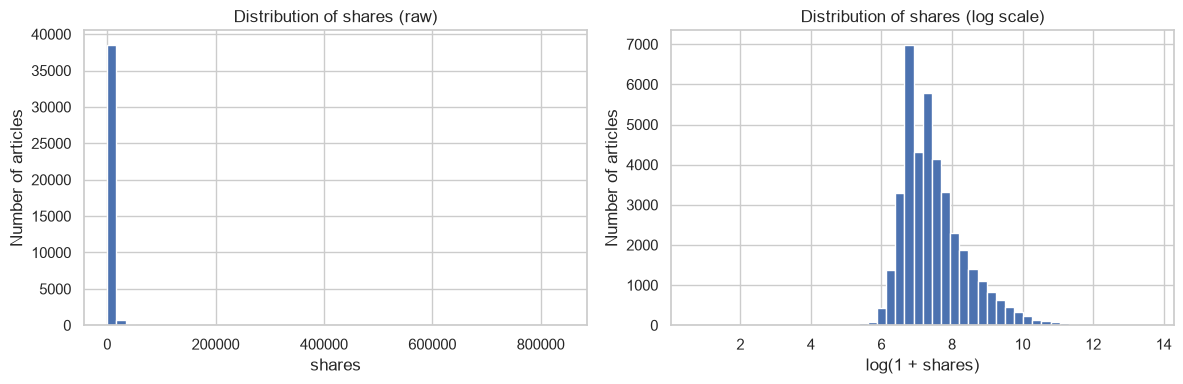

In [14]:
# ---------- 2.2 Distribution of article shares ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: raw shares (most articles get squeezed into the first bar because of extreme values)
axes[0].hist(eda_df["shares"], bins=50)
axes[0].set_title("Distribution of shares (raw)")
axes[0].set_xlabel("shares")
axes[0].set_ylabel("Number of articles")

# Right: log scale makes the shape readable; log1p(x) = log(1 + x)
axes[1].hist(np.log1p(eda_df["shares"]), bins=50)
axes[1].set_title("Distribution of shares (log scale)")
axes[1].set_xlabel("log(1 + shares)")
axes[1].set_ylabel("Number of articles")

plt.tight_layout()
plt.show()

In [15]:
# Percentiles show how lopsided shares are (e.g. what the top 1% of articles reach)
print(eda_df["shares"].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))
print("Skewness:", round(eda_df["shares"].skew(), 2))

0.25      946.0
0.50     1400.0
0.75     2800.0
0.90     6200.0
0.95    10800.0
0.99    31657.0
Name: shares, dtype: float64
Skewness: 33.96


In [16]:
# ---------- 2.3 Correlation analysis ----------
# Correlation matrix: every numeric column against every other (-1 to +1, 0 = no linear link)
corr_matrix = numeric_df.corr()

# Correlation of each feature with shares, strongest first (sign ignored for sorting)
shares_corr = corr_matrix["shares"].drop("shares")
shares_corr = shares_corr.reindex(shares_corr.abs().sort_values(ascending=False).index)
print(shares_corr.head(10))

kw_avg_avg                    0.110413
kw_max_avg                    0.064306
self_reference_avg_sharess    0.057789
self_reference_min_shares     0.055958
data_channel_is_world        -0.049497
self_reference_max_shares     0.047115
num_hrefs                     0.045404
kw_avg_max                    0.044686
kw_min_avg                    0.039551
num_imgs                      0.039388
Name: shares, dtype: float64


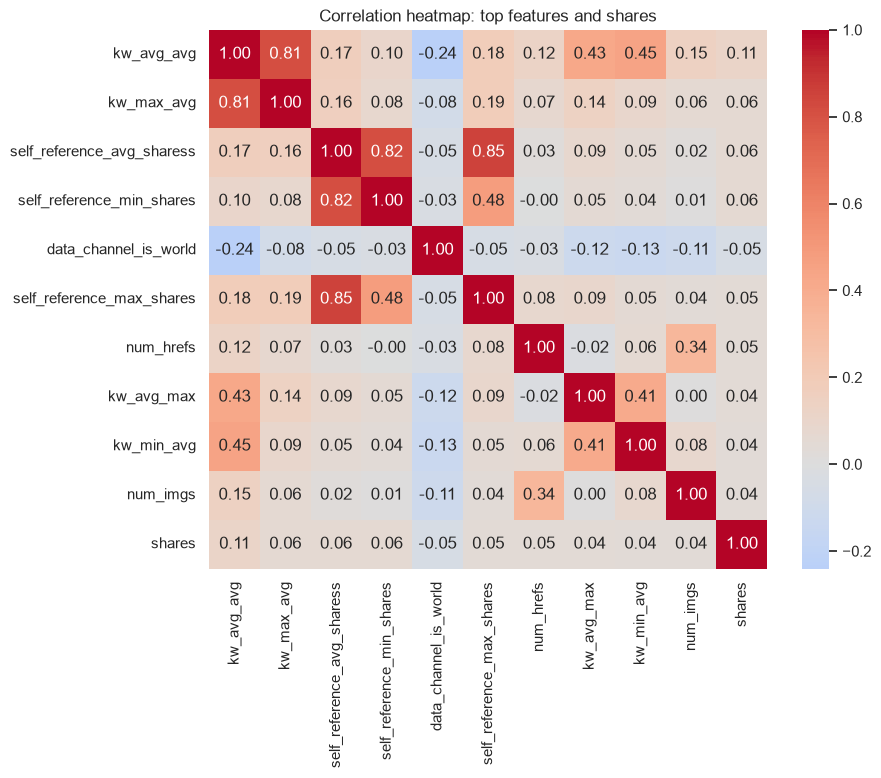

In [17]:
# Heatmap of the 10 features most correlated with shares (all columns would be unreadable)
top_features = shares_corr.head(10).index.tolist() + ["shares"]

plt.figure(figsize=(9, 7))
sns.heatmap(numeric_df[top_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap: top features and shares")
plt.show()

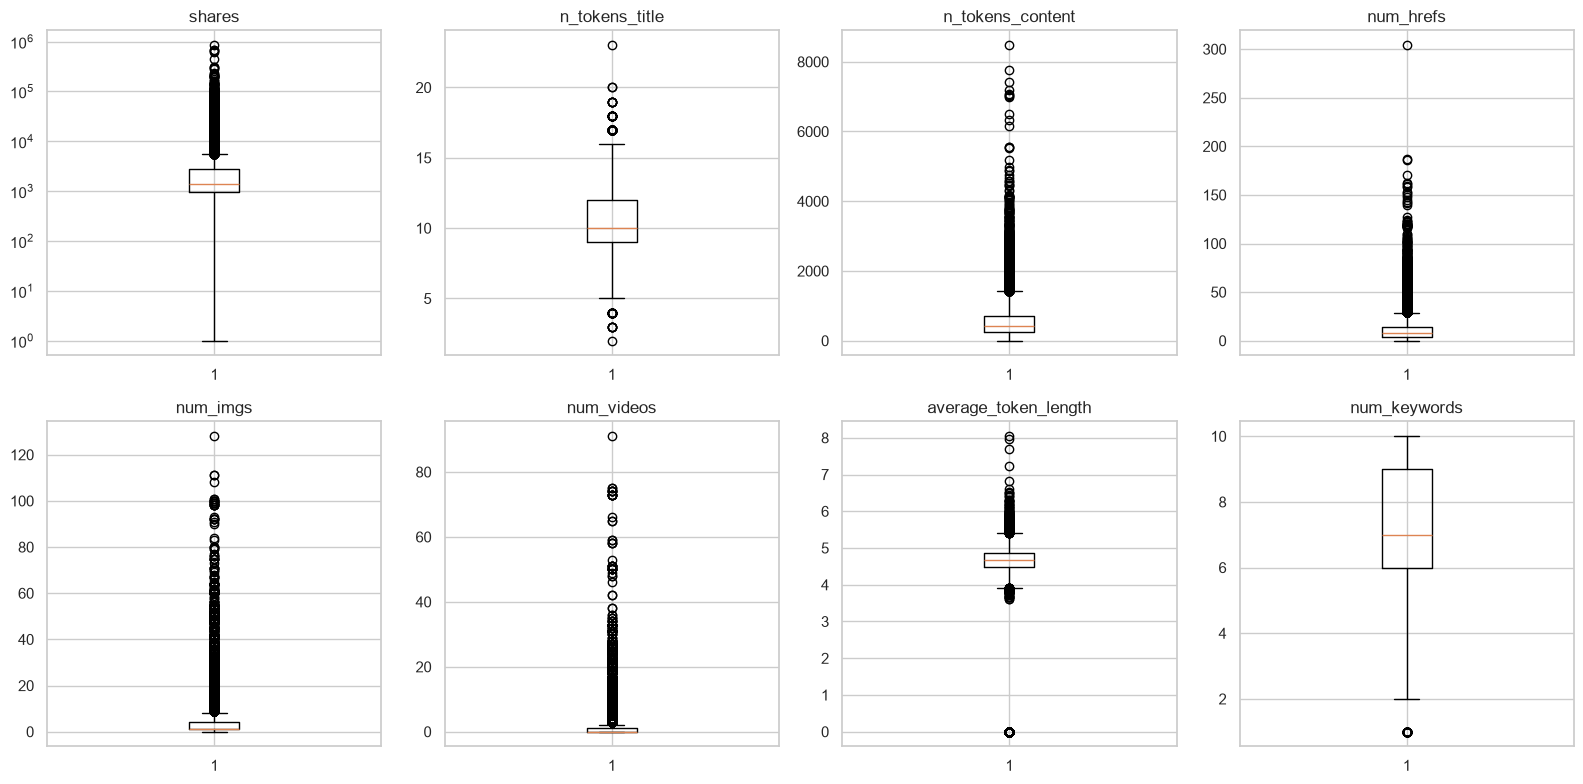

In [18]:
# ---------- 2.4 Outlier visualisation using boxplots ----------
# shares plus the main article-size and content features
box_columns = [
    "shares", "n_tokens_title", "n_tokens_content", "num_hrefs",
    "num_imgs", "num_videos", "average_token_length", "num_keywords",
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), box_columns):
    ax.boxplot(eda_df[col].dropna())   # dots beyond the whiskers are outliers
    ax.set_title(col)

# shares is so extreme that it needs a log axis for the box to be visible
axes[0, 0].set_yscale("log")

plt.tight_layout()
plt.show()

In [19]:
# Count outliers with the IQR rule (below Q1 - 1.5*IQR or above Q3 + 1.5*IQR)
# Only counted for reporting: nothing is removed (Phase 1 kept outliers on purpose)
rows = []
for col in box_columns:
    q1, q3 = eda_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((eda_df[col] < q1 - 1.5 * iqr) | (eda_df[col] > q3 + 1.5 * iqr)).sum()
    rows.append({"column": col, "outliers": n_out, "percent": round(100 * n_out / len(eda_df), 1)})

pd.DataFrame(rows).set_index("column")

,outliers,percent
column,,
shares,4541,11.5
n_tokens_title,156,0.4
n_tokens_content,1933,4.9
num_hrefs,2169,5.5
num_imgs,7703,19.4
num_videos,2946,7.4
average_token_length,1681,4.2
num_keywords,51,0.1


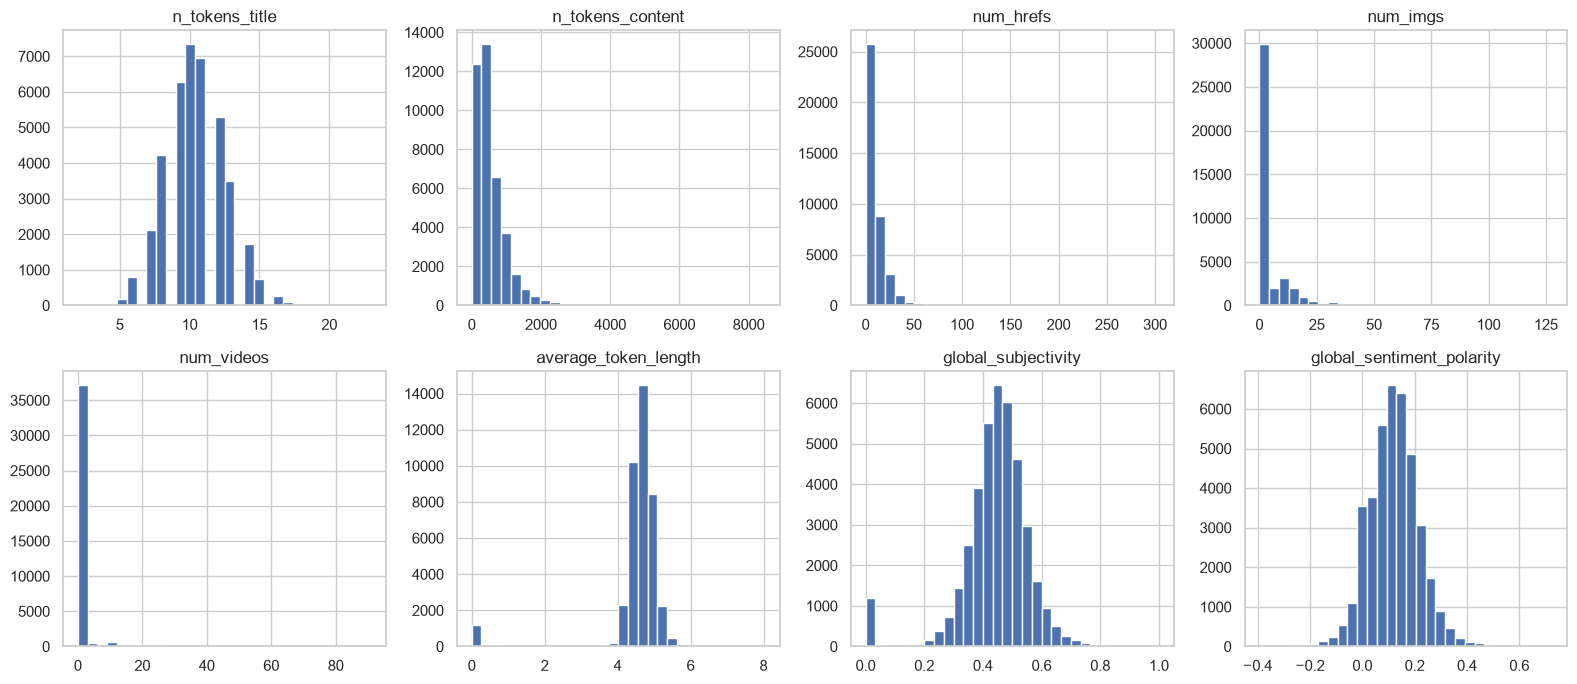

In [20]:
# ---------- 2.5 Histograms, scatter plots and bar charts ----------
# Histograms: how the values of key features are spread
hist_columns = [
    "n_tokens_title", "n_tokens_content", "num_hrefs", "num_imgs",
    "num_videos", "average_token_length", "global_subjectivity", "global_sentiment_polarity",
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), hist_columns):
    ax.hist(eda_df[col], bins=30)
    ax.set_title(col)

plt.tight_layout()
plt.show()

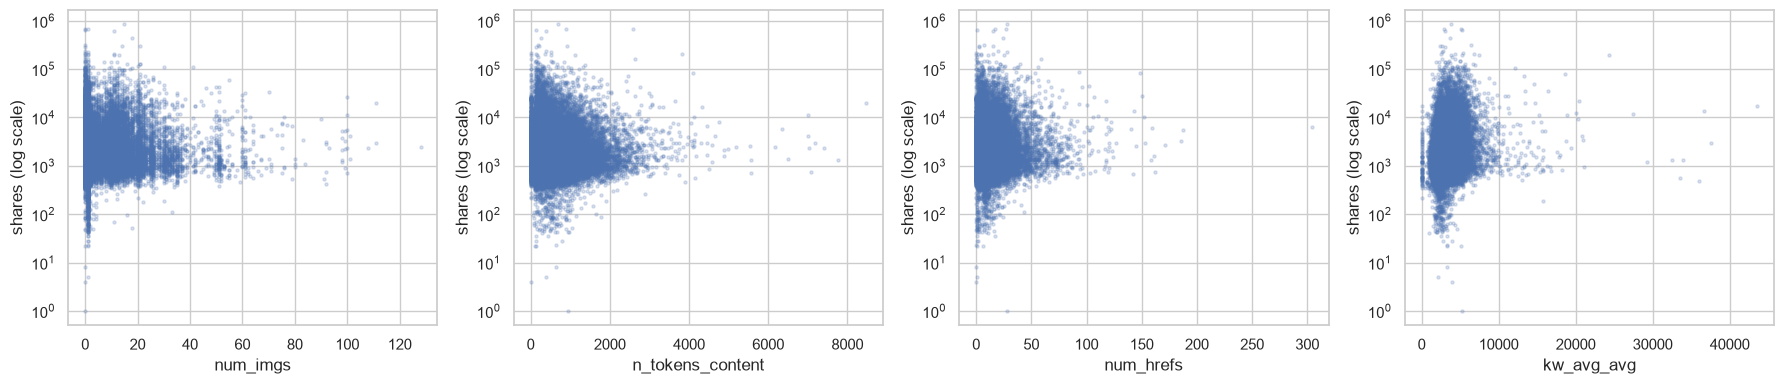

In [21]:
# Scatter plots: shares against four features (log y-axis because shares is very skewed)
scatter_columns = ["num_imgs", "n_tokens_content", "num_hrefs", "kw_avg_avg"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, scatter_columns):
    ax.scatter(eda_df[col], eda_df["shares"], alpha=0.2, s=5)
    ax.set_yscale("log")
    ax.set_xlabel(col)
    ax.set_ylabel("shares (log scale)")

plt.tight_layout()
plt.show()

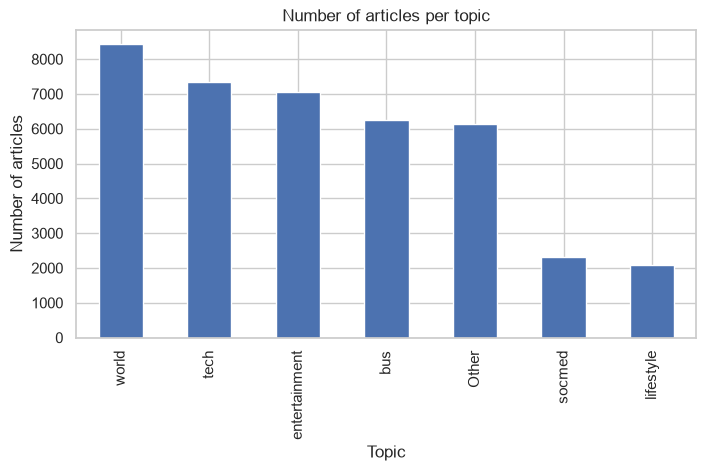

In [22]:
# Bar chart: number of articles in each topic
eda_df["channel"].value_counts().plot(kind="bar", figsize=(8, 4))
plt.title("Number of articles per topic")
plt.xlabel("Topic")
plt.ylabel("Number of articles")
plt.show()

In [23]:
# ---------- 2.6 Compare average shares across topics and publication days ----------
# Mean and median shares per topic (median shown too because viral articles inflate the mean)
channel_shares = (
    eda_df.groupby("channel")["shares"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)
channel_shares

,mean,median,count
channel,,,
Other,5945.189599,1900.0,6134
lifestyle,3682.123392,1700.0,2099
socmed,3629.383125,2100.0,2323
tech,3072.283283,1700.0,7346
bus,3063.018536,1400.0,6258
entertainment,2970.487034,1200.0,7057
world,2287.734069,1100.0,8427


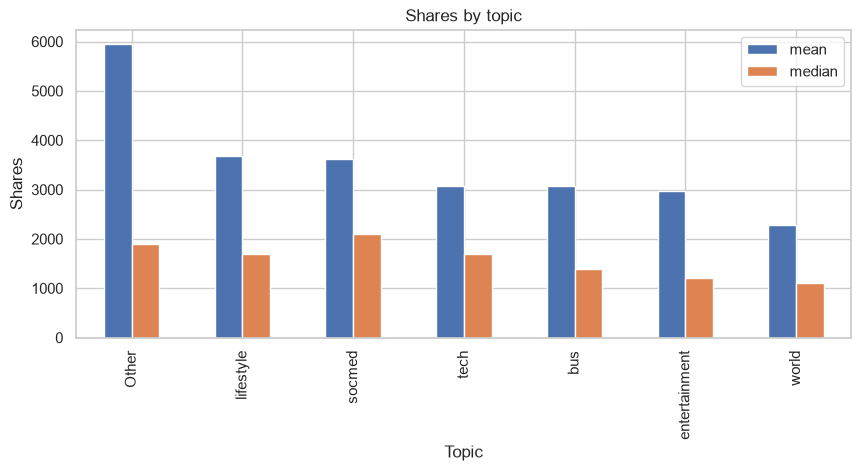

In [24]:
# Bar chart of mean vs median shares per topic
channel_shares[["mean", "median"]].plot(kind="bar", figsize=(10, 4))
plt.title("Shares by topic")
plt.xlabel("Topic")
plt.ylabel("Shares")
plt.show()

In [25]:
# Mean and median shares per publication day, in weekday order
day_shares = (
    eda_df.groupby("weekday")["shares"]
    .agg(["mean", "median", "count"])
    .reindex(day_order)
)
day_shares

,mean,median,count
weekday,,,
Monday,3647.025822,1400.0,6661
Tuesday,3202.500677,1300.0,7390
Wednesday,3303.405380,1300.0,7435
Thursday,3178.599147,1400.0,7267
Friday,3285.181021,1500.0,5701
Saturday,4078.185079,2000.0,2453
Sunday,3746.740592,1900.0,2737


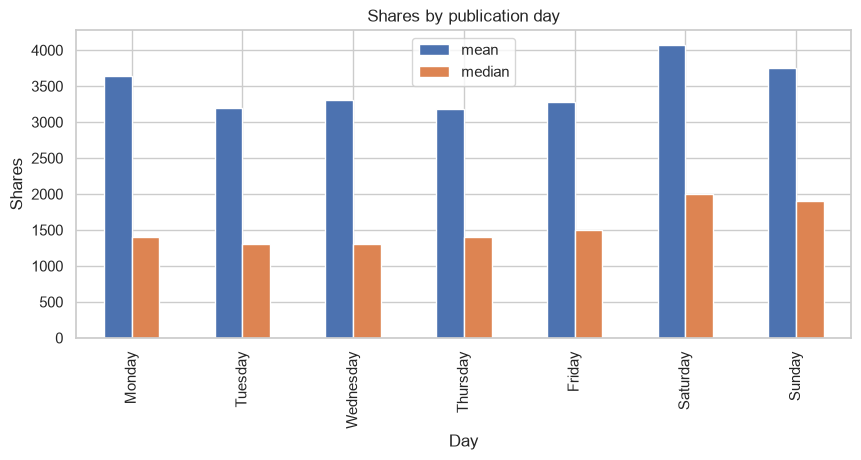

In [26]:
# Bar chart of mean vs median shares per publication day
day_shares[["mean", "median"]].plot(kind="bar", figsize=(10, 4))
plt.title("Shares by publication day")
plt.xlabel("Day")
plt.ylabel("Shares")
plt.show()

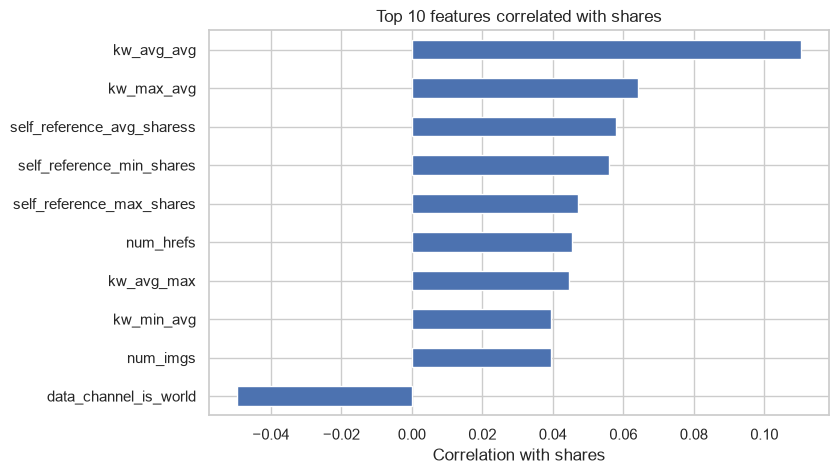

In [27]:
# ---------- 2.7 Identify features associated with popularity ----------
# Top 10 features by correlation with shares (computed in 2.3)
top10 = shares_corr.head(10)

top10.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 features correlated with shares")
plt.xlabel("Correlation with shares")
plt.show()

In [28]:
# Popular = shares at or above the median (same rule Phase 1 used for y2)
eda_df["popular"] = (eda_df["shares"] >= eda_df["shares"].median()).astype(int)

# Average value of the top 10 features for popular vs not-popular articles
popular_compare = eda_df.groupby("popular")[top10.index].mean().T
popular_compare = popular_compare.rename(columns={0: "Not popular", 1: "Popular"})
popular_compare

popular,Not popular,Popular
kw_avg_avg,2913.395119,3330.306521
kw_max_avg,5197.340772,6059.168384
self_reference_avg_sharess,4710.564910,7879.859775
self_reference_min_shares,2881.673140,4975.159428
data_channel_is_world,0.280043,0.153588
self_reference_max_shares,7666.986381,12656.175125
num_hrefs,9.790049,11.839605
kw_avg_max,256992.364423,261283.177422
kw_min_avg,1006.788951,1213.606528
num_imgs,3.946944,5.066134
